In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
# Student dataset
data = {
    "Hours_Studied": [1,2,3,4,5,6,7,8,2,6,7,3],
    "Attendance":    [50,55,60,65,70,80,85,90,40,75,88,58],
    "Result":        [0,0,0,0,1,1,1,1,0,1,1,0]  # 0=Fail, 1=Pass
}

In [ ]:
df = pd.DataFrame(data)
df

,Hours_Studied,Attendance,Result
0,1,50,0
1,2,55,0
2,3,60,0
3,4,65,0
4,5,70,1
5,6,80,1
6,7,85,1
7,8,90,1
8,2,40,0
9,6,75,1


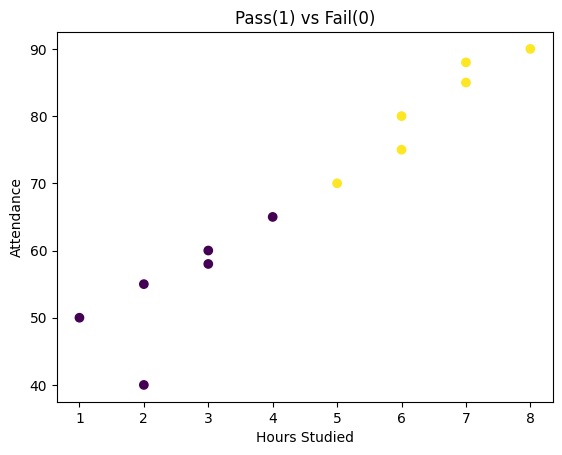

In [ ]:
plt.scatter(df["Hours_Studied"], df["Attendance"], c=df["Result"])
plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.title("Pass(1) vs Fail(0)")
plt.show()

In [ ]:
X = df[["Hours_Studied", "Attendance"]]
y = df["Result"]

In [ ]:
X

,Hours_Studied,Attendance
0,1,50
1,2,55
2,3,60
3,4,65
4,5,70
5,6,80
6,7,85
7,8,90
8,2,40
9,6,75


In [ ]:
model = LogisticRegression()
model.fit(X, y)

LogisticRegression()

In [ ]:
predictions = model.predict(X)
predictions

array([0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0])

In [ ]:
data

{'Hours_Studied': [1, 2, 3, 4, 5, 6, 7, 8, 2, 6, 7, 3],
 'Attendance': [50, 55, 60, 65, 70, 80, 85, 90, 40, 75, 88, 58],
 'Result': [0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0]}

In [ ]:
new_student = pd.DataFrame({
    "Hours_Studied":[5],
    "Attendance":[75]
})

model.predict(new_student)

array([1])

In [ ]:
print(model.classes_)
model.predict_proba(new_student)

[0 1]


array([[0.00407951, 0.99592049]])

In [ ]:
accuracy = accuracy_score(y, predictions)
print("Accuracy:", accuracy)

Accuracy: 1.0


In [ ]:
new_student = pd.DataFrame({
    "Hours_Studied":[3],
    "Attendance":[90]
})

model.predict(new_student)

array([1])

In [ ]:
cm = confusion_matrix(y, predictions)
print(cm)

[[6 0]
 [0 6]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


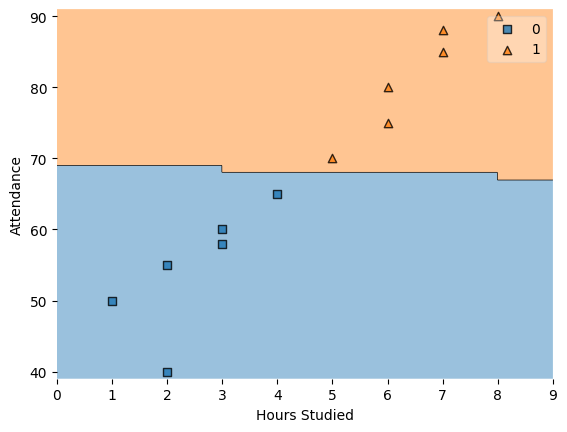

In [ ]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X.values, y.values, clf=model)
plt.xlabel("Hours Studied")
plt.ylabel("Attendance")
plt.show()

---
## 🩺 Logistic Regression: Predicting Categories

Linear Regression predicts a *continuous number* (like House Price).
**Logistic Regression** predicts a *category* (0 or 1, Yes or No).

Instead of a straight line, Logistic Regression uses an **S-Curve (Sigmoid)** to squeeze the predictions between 0 (0%) and 1 (100%).

### 🔬 Real-World Project: Breast Cancer Diagnosis
Let's use the famous Breast Cancer dataset. We will give the AI measurements of a tumor (radius, texture, smoothness) and ask it to predict:
* **0 = Benign** (Not dangerous)
* **1 = Malignant** (Dangerous/Cancerous)

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load the Breast Cancer dataset
cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = cancer_data.target  # 0 = Malignant, 1 = Benign
# (Note: Sklearn defaults Malignant=0, Benign=1. We'll leave it as is!)

print("Here are the tumor features the AI will look at:")
display(X.head(3))

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Here are the tumor features the AI will look at:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


### ⚖️ The Secret Step: Feature Scaling
The AI looks at 30 different measurements. Some numbers are tiny (`smoothness = 0.05`) and some are massive (`area = 1000.0`).

If we feed this directly into Logistic Regression, the math engine gets confused and crashes (it fails to "converge"). To fix this, we use a **StandardScaler**. It shrinks all the columns down to the exact same scale so the AI can compare them fairly!

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Initialize the Scaler
scaler = StandardScaler()

# 2. FIT (learn the min/max) and TRANSFORM the Training data
X_train_scaled = scaler.fit_transform(X_train)

# 3. ONLY TRANSFORM the Test data (Never fit on the test data!)
X_test_scaled = scaler.transform(X_test)

# 4. Create the Logistic Regression Model
# (Because the data is scaled, we don't even need max_iter=3000 anymore!)
log_model = LogisticRegression()

# 5. Train the model on the SCALED data
log_model.fit(X_train_scaled, y_train)

print("✅ Logistic Regression Model Trained Successfully (Without Warnings)!")

✅ Logistic Regression Model Trained Successfully (Without Warnings)!


AI Diagnostic Accuracy: 97.37%



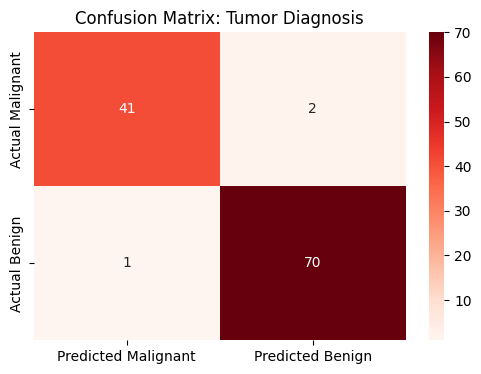

In [ ]:
# 5. Make predictions on the SCALED Test set
predictions = log_model.predict(X_test_scaled)

# 6. Check Accuracy
acc = accuracy_score(y_test, predictions)
print(f"AI Diagnostic Accuracy: {acc * 100:.2f}%\n")

# 7. Visualize the Confusion Matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Predicted Malignant', 'Predicted Benign'],
            yticklabels=['Actual Malignant', 'Actual Benign'])
plt.title("Confusion Matrix: Tumor Diagnosis")
plt.show()

---

## 🌉 The Bridge to Deep Learning: What did Logistic Regression just do?

We just trained a **Logistic Regression** model. But how did it actually make its decision mathematically?

Behind the scenes, it did exactly two things:

**1. It calculated a straight line (Weighted Sum):**
It gave a "weight" ($w$) to each feature and added a bias ($b$).

$z = w_1(\text{Hours_Studied}) + w_2(\text{Attendance}) + b$

**2. It applied the S-Curve (Sigmoid):**
It took that straight line ($z$) and squished it into a probability between 0 and 1 using the Sigmoid function ($\sigma$).

$P(\text{Pass}) = \sigma(z) = \frac{1}{1 + e^{-z}}$

---

Look closely at the math above. In the world of Statistics, we call this **Logistic Regression**.

But in the world of Artificial Intelligence and Deep Learning, if you draw this exact same math equation as a circle with inputs and outputs, it is called a **Single Layer Perceptron (SLP)**!

**Logistic Regression IS a Single Layer Perceptron (with a Sigmoid activation).**
It is the fundamental building block (a single artificial neuron) of a neural network. Let's look at how we build this exact same "brain cell" using Deep Learning code (PyTorch)!


# Single Layer Perceptron (SLP)

A **Single Layer Perceptron** is the simplest form of neural network.  
It takes multiple input features, computes a weighted sum, adds a bias term, and applies an activation function.

In this notebook, we use two important student features:

- **Hours_Studied**
- **Attendance**

to predict whether a student will **Pass (1)** or **Fail (0)**.

---

## Mathematical Representation

For two input features:


$z = w_1(\text{Hours_Studied}) + w_2(\text{Attendance}) + b$

Output:


$y = \sigma(z)$


where:

- $(w_1, w_2)$ are weights
- $b$ is bias
- $\sigma$ is the sigmoid activation function

---

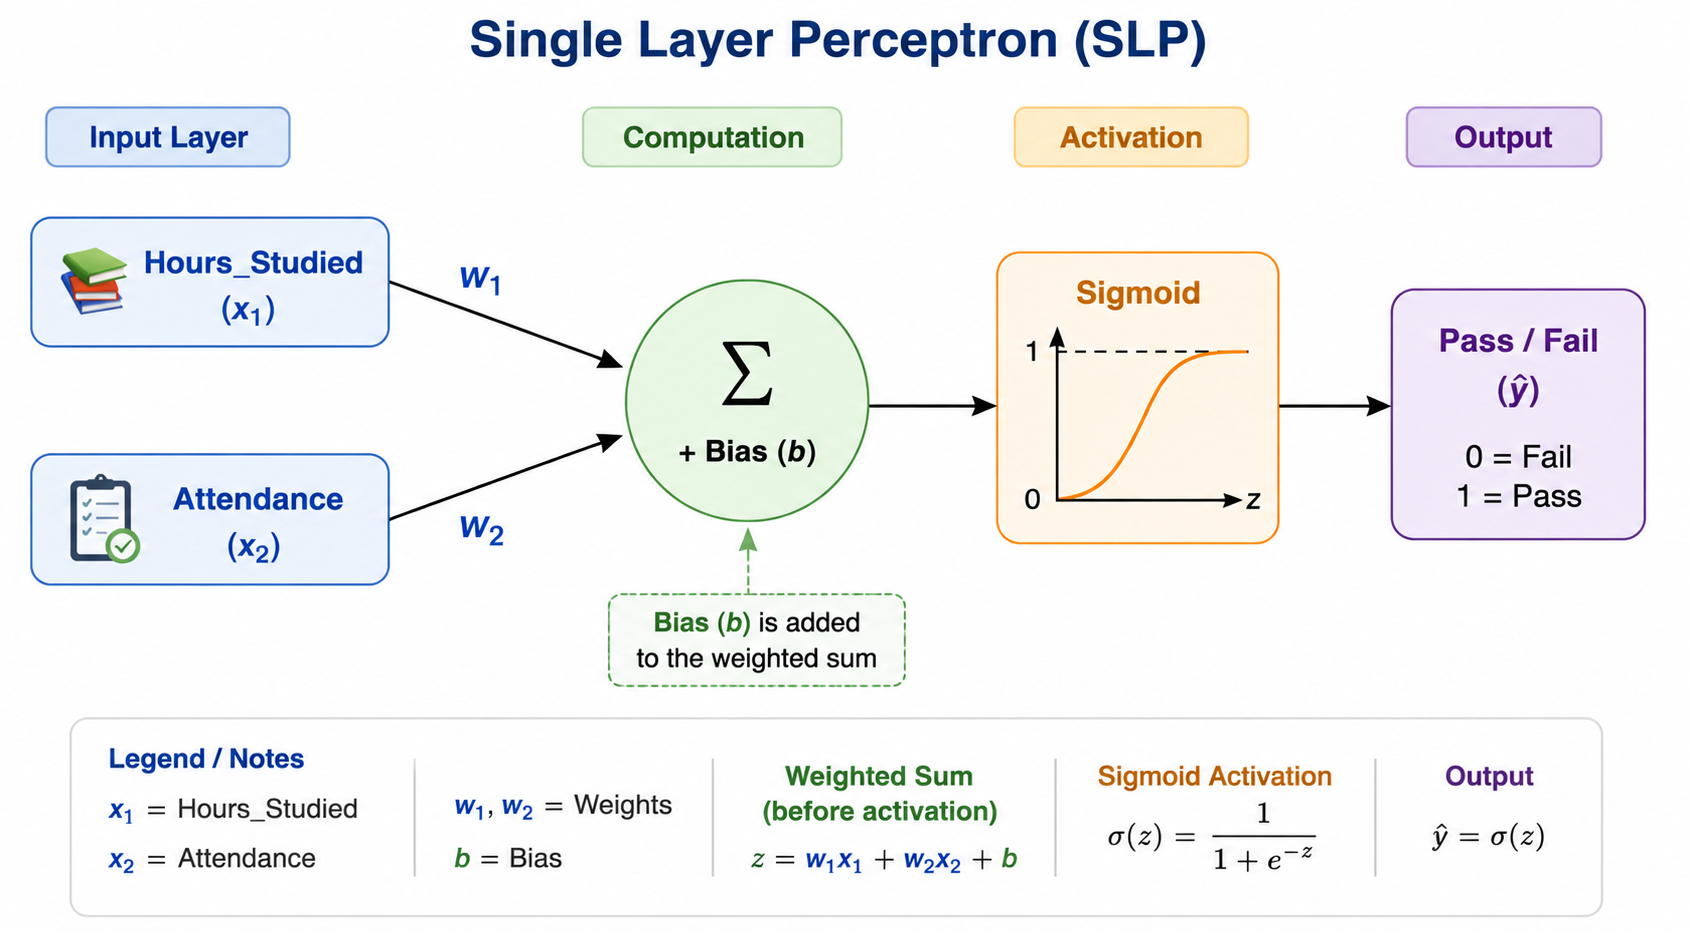
---

## Key Characteristics

- Only one trainable layer
- Works well for linearly separable data
- Fast and simple
- Cannot model highly complex patterns


---
## 🧮 The 4 Math Pillars of Neural Networks
Before we look at the architecture of an Artificial Brain, we need to understand the 4 simple math steps it uses to think and learn. Don't worry, no calculus required!

**1. The Weighted Sum ($\Sigma$)**
The brain takes your inputs ($x$), multiplies them by an importance factor called a weight ($w$), and adds them all together. It also adds a Bias ($b$) to shift the result.
* *Equation: $z = w_1x_1 + w_2x_2 + b$*

**2. The Activation Function ($f$)**
The weighted sum ($z$) can be a massive, crazy number. The Activation Function acts as a filter or "gatekeeper".
* **Sigmoid** squishes the number between 0 and 1 (giving us a probability).
* **ReLU** turns any negative number into a 0, but leaves positive numbers alone.

**3. The Loss Function (The Scoreboard)**
After the network makes a guess, it checks the real answer. The Loss Function measures exactly how wrong the guess was. (High Loss = Bad, Zero Loss = Perfect).

**4. Gradient Descent (How it Learns)**
How does the machine actually get smarter? Imagine a blindfolded hiker trying to find the lowest valley on a mountain. The machine checks the slope of the error, takes a step downhill by adjusting its weights ($w$) slightly, and guesses again. It repeats this thousands of times until it reaches the bottom of the valley (Zero Error)!

---
## 🎛️ The AI Control Panel (Hyperparameters)

When we train an Artificial Neural Network, the machine learns the **Weights and Biases** entirely on its own. However, *we* (the humans) have to configure the settings of the brain before we press start! We call these human settings **Hyperparameters**.

Here are the 3 settings we will control in our code today:

**1. Hidden Layers (`hidden_layer_sizes`)**
How big is the brain? If we set it to `(10, 5)`, we are creating two hidden layers of neurons. A committee of 10 neurons will look at the data, and pass their findings to a second committee of 5 neurons.

**2. Epochs (`max_iter`)**
How many times should the AI study the data? An **Epoch** is one complete read-through of the entire dataset. Just like humans studying for a test, reading the data 1 time isn't enough. We usually set this to 500 or 1000 so the AI has time to memorize the patterns.

**3. Learning Rate (`learning_rate_init`)**
Remember our blindfolded hiker stepping down the mountain to minimize the error? The Learning Rate is the **size of their steps**.
* If the step is too big, the AI jumps completely over the solution!
* If the step is too small, it takes forever to finish training.
* We usually leave this at a small "Goldilocks" number, like `0.001`.
---

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

In [32]:
# Student features: Hours_Studied and Attendance

X = torch.tensor([
    [1.0, 50.0],
    [2.0, 55.0],
    [3.0, 60.0],
    [4.0, 65.0],
    [5.0, 70.0],
    [6.0, 80.0],
    [7.0, 85.0],
    [8.0, 90.0]
])

y = torch.tensor([
    [0.0],
    [0.0],
    [0.0],
    [0.0],
    [1.0],
    [1.0],
    [1.0],
    [1.0]
])

In [44]:
# Single Layer Perceptron (SLP)

model = nn.Sequential(
    nn.Linear(2,1),
    nn.Sigmoid()
)

In [45]:
criterion = nn.BCELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)

In [46]:
for epoch in range(200):
    y_pred = model(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("Training complete")

Training complete


In [47]:
test = torch.tensor([[6.0, 78.0]])
prediction = model(test)

print("Pass probability:", prediction.item())

Pass probability: 1.0



# Multi Layer Perceptron (MLP)

A **Multi Layer Perceptron (MLP)** extends the perceptron by adding one or more hidden layers.

This allows the network to learn more complex relationships between:

- **Hours_Studied**
- **Attendance**
- Final Result (Pass/Fail)

---

## Architecture of MLP

An MLP generally contains:

1. Input Layer
2. Hidden Layer(s)
3. Output Layer

---
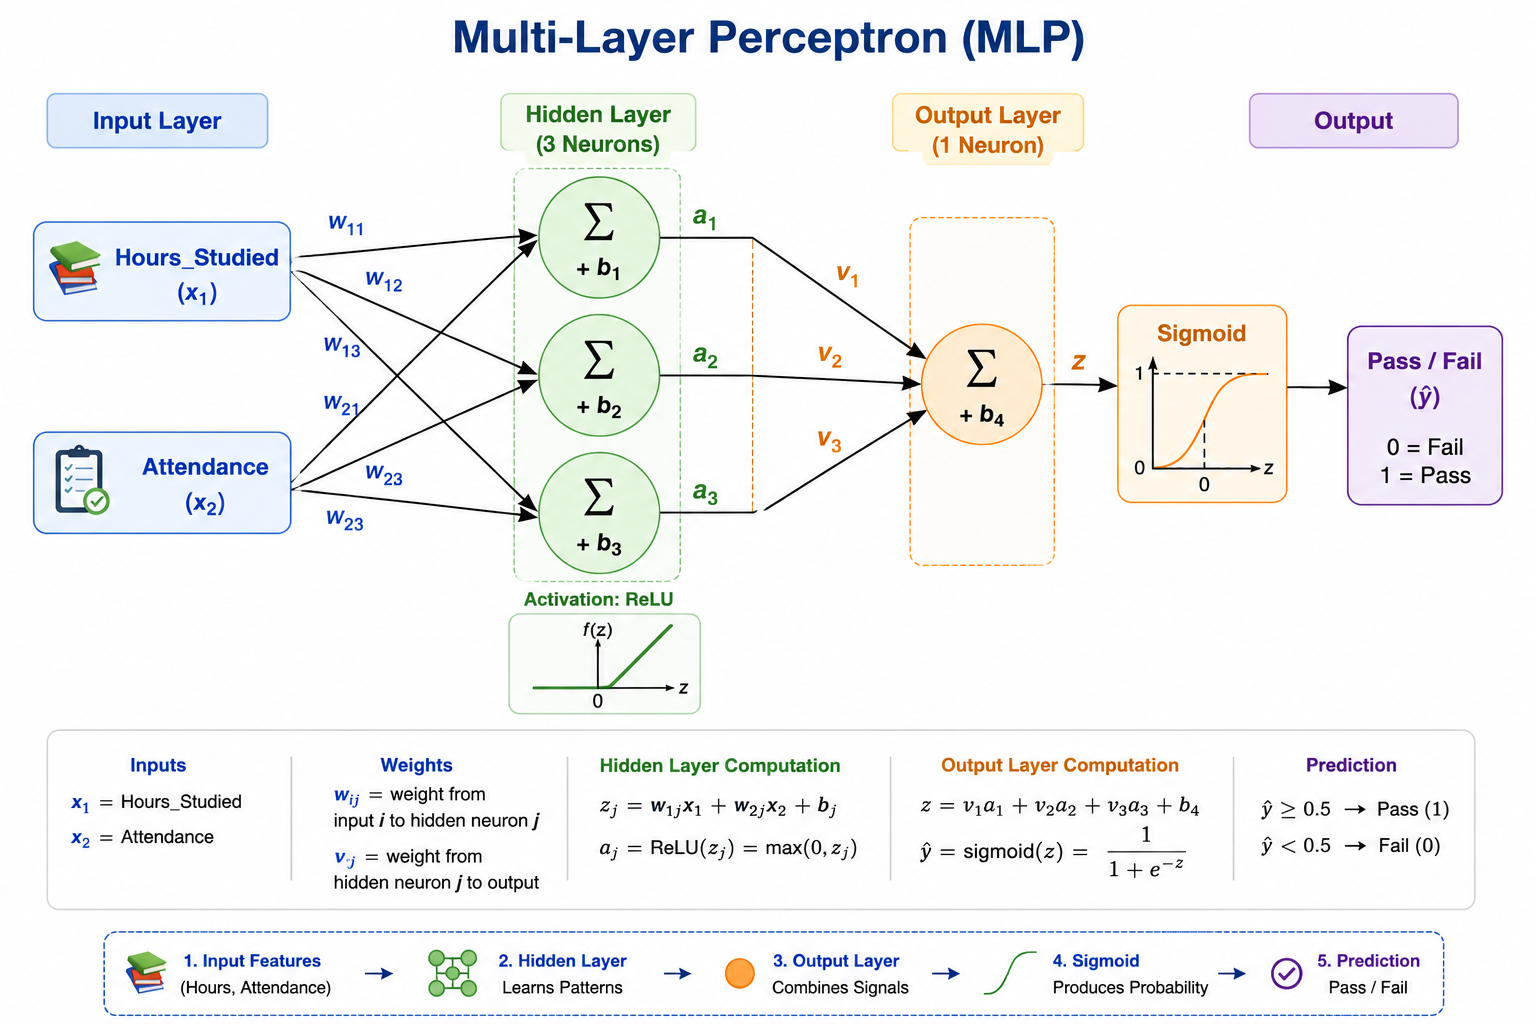

---

## Why MLP is More Powerful

Compared to a Single Layer Perceptron:

- Learns non-linear relationships
- Captures interactions between Hours_Studied and Attendance
- Better generalization capability
- Foundation of Deep Learning

---


## Training Process

1. Forward Propagation
2. Loss Computation
3. Backpropagation
4. Weight Update
5. Repeat for many epochs

---

## Comparison: SLP vs MLP

| Feature | SLP | MLP |
|---|---|---|
| Hidden Layers | No | Yes |
| Complexity | Low | High |
| Non-linear Learning | No | Yes |
| Computational Cost | Low | Higher |
| Real-world Usage | Limited | Very Common |


In [ ]:
# Multi Layer Perceptron (MLP)

mlp = nn.Sequential(
    nn.Linear(2,5),
    nn.ReLU(),
    nn.Linear(5,1),
    nn.Sigmoid()
)

In [ ]:
test

tensor([[ 6., 78.]])

In [ ]:
optimizer = optim.SGD(mlp.parameters(), lr=0.1)

for epoch in range(200):
    y_pred = mlp(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("MLP training done")

MLP training done


In [ ]:
# 1. Get the probability from the model
prediction = mlp(test)
probability = prediction.item()

print(f"MLP pass probability: {probability * 100:.2f}%")

# 2. Convert the probability to a Class (0 or 1) using a 0.5 threshold
if probability >= 0.5:
    predicted_class = 1
    print("Predicted Class: 1 (PASS) ✅")
else:
    predicted_class = 0
    print("Predicted Class: 0 (FAIL) ❌")

MLP pass probability: 100.00%
Predicted Class: 1 (PASS) ✅



# Understanding the Decision Boundary

The model learns how both:

- Higher study hours
- Better attendance

increase the probability of passing.

The neural network automatically learns the importance of each feature using weights during training.

For example:

- A student with low study hours but excellent attendance may still pass.
- A student with high study hours but poor attendance may have lower probability.

This demonstrates how neural networks combine multiple features for intelligent prediction.
